# Week 11 — Visualization I: Dask and Datashader

Read partitioned data, aggregate points into pixels, and compare density and category maps.

**Examples:** OpenStreetMap GPS points and historical Census dots.

<a href="Visualizing%20Large%20Data-Lec1.ipynb" download>Download notebook</a> · [Next: Visualization II](Visualizing%20Large%20Data-Lec2.html) · [LiDAR processing](lecture-11B.html)


## Before you start

Use **Python (largeviz)** for all three Week 11 sections. Download <a href="environment-viz.yml" download>environment-viz.yml</a> beside the notebooks. In a terminal opened in this lab folder:

```bash
# First time only:
conda env create -f environment-viz.yml
# If largeviz already exists, update it instead:
# conda env update -n largeviz -f environment-viz.yml
conda activate largeviz
python -m ipykernel install --user --name largeviz --display-name "Python (largeviz)"
jupyter lab
```

In VS Code, open the notebook and select **Python (largeviz)**. Run the cells from top to bottom. See the [README](README.md) for setup troubleshooting.


## Download the data first

1. Create a local folder named `week11` and save <a href="Visualizing%20Large%20Data-Lec1.ipynb" download>this notebook</a> and <a href="environment-viz.yml" download>environment-viz.yml</a> there.
2. Create `data/samples/` inside `week11`.
3. Download each file below into that folder. Keep the exact filename. If a link opens in the browser, right-click and choose **Save Link As…**.

| Download | Save locally as |
| --- | --- |
| [osm_sample.parquet](data/samples/osm_sample.parquet) | `data/samples/osm_sample.parquet` |
| [census_sample.parquet](data/samples/census_sample.parquet) | `data/samples/census_sample.parquet` |

Open the notebook from `week11` and select **Python (largeviz)**. Paths below are relative to that folder. Files are read locally; no automatic downloads or hidden caches are used.

The files are teaching extracts, not the full billion-point archives or representative population/travel estimates. Census dots have synthetic locations. See [sources and sampling](data/samples/provenance.json). For a full local Parquet dataset, change its filename below to your Parquet folder; keep the lazy Dask workflow.


## 1. Import the packages

Dask handles partitioned tables; Datashader converts point counts into a fixed-size image. Colorcet provides color maps.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import dask
import dask.dataframe as dd
import datashader as ds
import datashader.transfer_functions as tf
from datashader.utils import lnglat_to_meters
from colorcet import fire
import matplotlib.pyplot as plt
from IPython.display import display

# Files saved beside this notebook, following the folder layout above.
DATA = Path("data/samples")
OUT = Path("outputs/viz1")
OUT.mkdir(parents=True, exist_ok=True)
print("Datashader", ds.__version__, "| Dask", dask.__version__)

/opt/anaconda3/envs/largeviz/lib/python3.12/site-packages/datashader/__init__.py:6: FutureWarning: param.version.Version has been deprecated and will be removed in a future version.
  __version__ = str(param.version.Version(fpath=__file__, archive_commit="$Format:%h$",
/opt/anaconda3/envs/largeviz/lib/python3.12/site-packages/param/version.py:200: FutureWarning: param.version.run_cmd has been deprecated and will be removed in a future version.
  remotes = run_cmd([cmd, 'remote', '-v'],


Datashader 0.16.2 | Dask 2024.5.0


## 2. Read GPS points with Dask

`read_parquet()` creates a lazy table. `head()` reads a few rows so we can inspect the columns.


In [2]:
osm = dd.read_parquet(DATA / "osm_sample.parquet", columns=["x", "y"],
                      engine="pyarrow", split_row_groups=True)
print("Partitions:", osm.npartitions)
osm.head()

Partitions: 21


,x,y
0,-7000458.5,-9536415.0
1,-7141858.0,-9664043.0
2,-7379035.0,-9890349.0
3,-7721307.5,-10498321.0
4,-7514765.5,-7346013.0


### Count the points

Use `dask.compute()` to calculate several summaries in one pass. The full table stays partitioned.


In [3]:
row_count, mean_x, mean_y = dask.compute(osm.shape[0], osm.x.mean(), osm.y.mean())
print(f"Extract rows: {row_count:,}; mean x={mean_x:,.0f}, y={mean_y:,.0f} meters")

Extract rows: 1,000,050; mean x=2,731,821, y=5,801,809 meters


### Aggregate points into pixels

Create a canvas, then count how many points fall in each pixel. The coordinates are Web Mercator meters; convert the map extent from longitude/latitude.


In [4]:
def mercator_extent(lon_bounds, lat_bounds):
    x, y = lnglat_to_meters(lon_bounds, lat_bounds)
    return tuple(x), tuple(y)

world_x, world_y = mercator_extent((-180, 180), (-70, 80))
canvas = ds.Canvas(plot_width=900, plot_height=450, x_range=world_x, y_range=world_y)
osm_count = canvas.points(osm, "x", "y", agg=ds.count())
print("Aggregate dimensions:", dict(osm_count.sizes))
print("Points inside this extent:", int(osm_count.sum()))

Aggregate dimensions: {'y': 450, 'x': 900}
Points inside this extent: 1000049


### Compare color scales

Shade the same counts three ways. Log and equalized scales reveal sparse areas; they change how counts map to color.


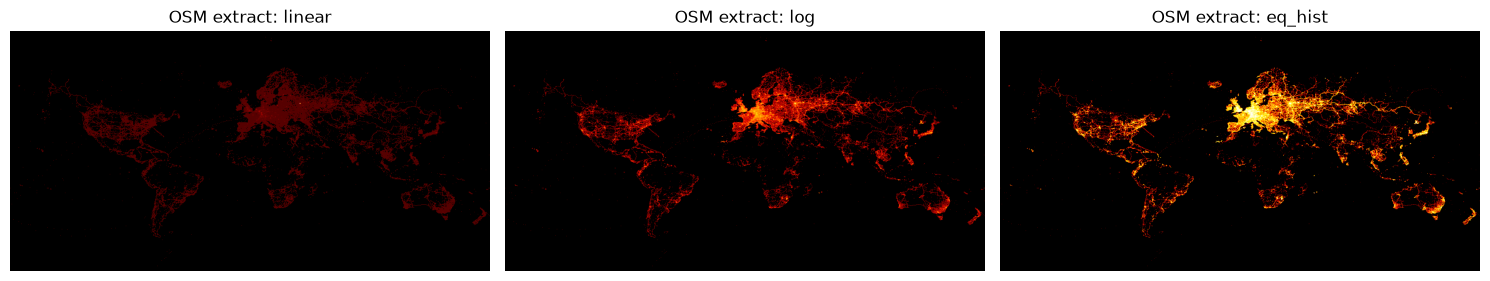

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, how in zip(axes, ["linear", "log", "eq_hist"]):
    image = tf.set_background(tf.shade(osm_count, cmap=fire[40:], how=how), "black")
    ax.imshow(image.to_pil())
    ax.set_title(f"OSM extract: {how}")
    ax.set_axis_off()
fig.tight_layout()
plt.show()

### Save a density map

Hide pixels with two or fewer points and save the image. Try a different threshold.


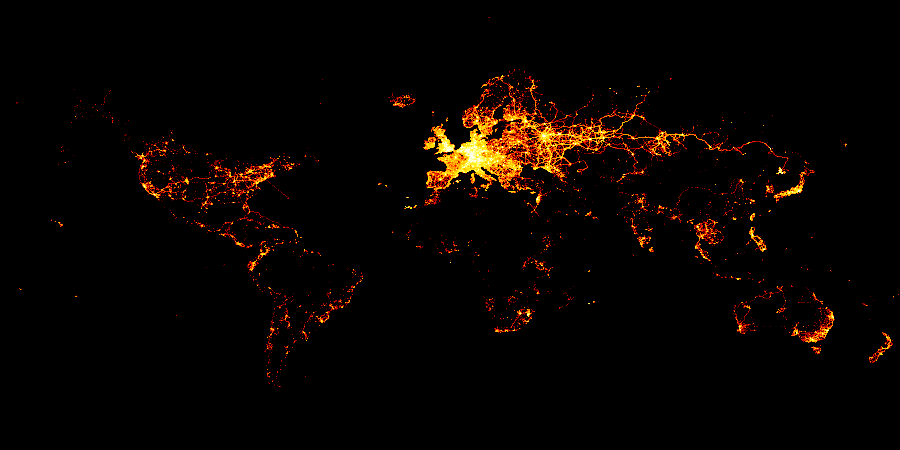

In [8]:
masked_osm = osm_count.where(osm_count > 2)
osm_image = tf.set_background(tf.shade(masked_osm, cmap=fire[40:], how="eq_hist"), "black")
osm_image.to_pil().save(OUT / "osm_density.png")
display(osm_image.to_pil())

## 3. Map Census categories

Read the Census extract and tell Datashader which categories to expect. `count_cat()` counts each category separately in every pixel. The labels come from the historical source data.


In [9]:
race_labels = {"w": "White", "b": "Black", "a": "Asian", "h": "Hispanic", "o": "Other"}
color_key = {"w": "#4cc9f0", "b": "#ffb703", "a": "#90be6d", "h": "#f28482", "o": "#cdb4db"}
census = dd.read_parquet(DATA / "census_sample.parquet", split_row_groups=True)
census["race"] = census["race"].astype(pd.CategoricalDtype(list(race_labels)))
census.head()

,easting,northing,race
0,-12352377.0,3676244.50,h
1,-12352691.0,3679306.75,h
2,-12352058.0,3677210.50,h
3,-12352007.0,3680322.75,h
4,-12351758.0,3677555.75,h


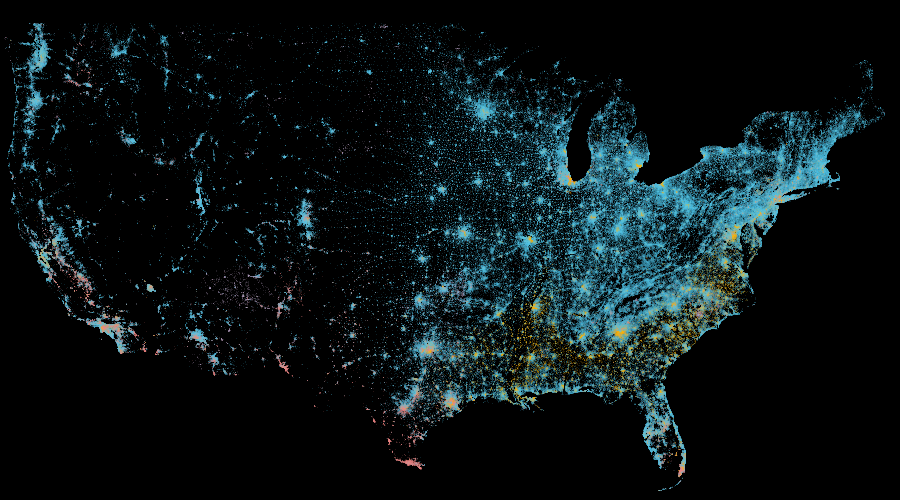

w       White
b       Black
a       Asian
h    Hispanic
o       Other
Name: Source category labels, dtype: object

In [11]:
usa_x, usa_y = mercator_extent((-125, -66), (24, 50))
census_canvas = ds.Canvas(plot_width=900, plot_height=500, x_range=usa_x, y_range=usa_y)
category_count = census_canvas.points(census, "easting", "northing", agg=ds.count_cat("race"))
census_image = tf.set_background(tf.shade(category_count, color_key=color_key, how="eq_hist"), "black")
display(census_image.to_pil())
pd.Series(race_labels, name="Source category labels")

### Map Census population density

Sum across categories, then compare linear and log color scales. These are counts of dots in the extract, not total population.


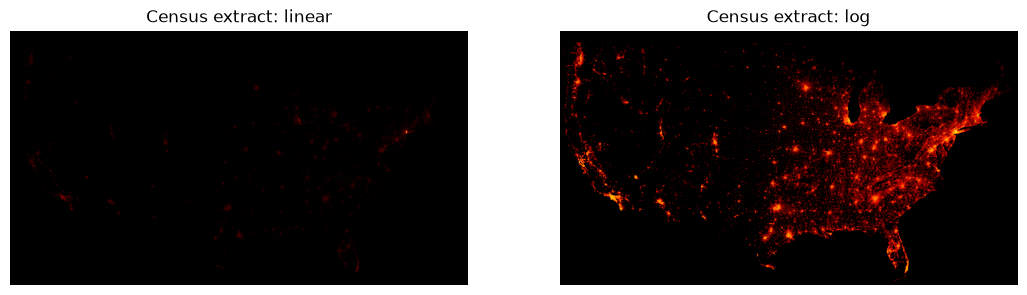

In [13]:
population = category_count.sum(dim="race")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, how in zip(axes, ["linear", "log"]):
    image = tf.set_background(tf.shade(population, cmap=fire, how=how), "black")
    ax.imshow(image.to_pil())
    ax.set_title(f"Census extract: {how}")
    ax.set_axis_off()
plt.show()


### Explore a city

Convert the longitude/latitude extent to Web Mercator with `lnglat_to_meters()`. Do not divide or multiply projected coordinates to imitate longitude/latitude. Datashader accepts planar coordinates; EPSG:3857 is used here to match the source data.


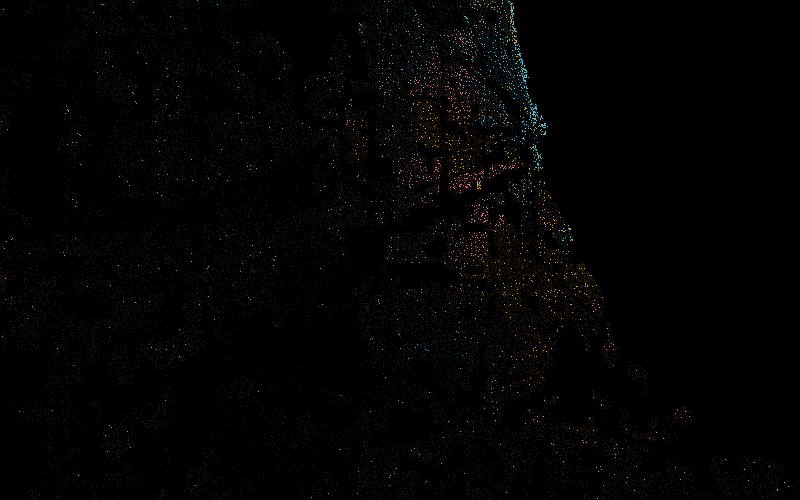

In [14]:
cities = {
    "USA": [(-125, -66), (24, 50)],
    "Chicago": [(-88.29, -87.30), (41.57, 42.00)],
    "New York": [(-74.39, -73.44), (40.51, 40.91)],
    "Philadelphia": [(-75.28, -74.96), (39.86, 40.14)],
    "Houston": [(-96.05, -94.68), (29.45, 30.11)],
}

def create_census_image(longitude_range, latitude_range):
    x_range, y_range = lnglat_to_meters(longitude_range, latitude_range)
    canvas = ds.Canvas(plot_width=800, plot_height=500, x_range=x_range, y_range=y_range)
    counts = canvas.points(census, "easting", "northing", agg=ds.count_cat("race"))
    return tf.set_background(tf.shade(counts, color_key=color_key, how="eq_hist"), "black")

city = "Chicago"
display(create_census_image(*cities[city]).to_pil())


### Save the image

The exported PNG is a fixed image. Change `city` above and rerun to export another extent.


In [15]:
create_census_image(*cities[city]).to_pil().save(OUT / "census_city.png")
print("Saved:", OUT / "census_city.png")


Saved: outputs/viz1/census_city.png


## Try it yourself

1. Change the OSM canvas width from 900 to 450. What changes about the image and aggregate size?
2. Compare linear, log, and equalized shading. Which reveals sparse areas?
3. Change `city` to Philadelphia or Houston. How does the thinned sample affect a close-up view?

**Next:** [Visualization II](Visualizing%20Large%20Data-Lec2.html) uses category queries, boundaries, taxi trips, and animation.
